In [1]:
import zipfile
import os
import pandas as pd

with zipfile.ZipFile("research_corpus.zip", "r") as z:
    z.extractall("research_corpus")


names = []
texts = []

for root, folders, files in os.walk("research_corpus"):
    for file in files:
        if file.endswith(".txt"):
            path = os.path.join(root, file)
            f = open(path, "r", encoding="utf-8", errors="ignore")
            texts.append(f.read())
            f.close()
            names.append(file)

df = pd.DataFrame({"article": names, "content": texts})
df["word_count"] = df["content"].apply(lambda x: len(x.split()))

print(df.shape)
df.head()

(5, 3)


,article,content,word_count
0,research_1.txt,The purposes of this article are to position m...,5602
1,research_2.txt,"Now I see it, now I don’t:\nresearcher’s posit...",2416
2,research_3.txt,DEVELOPMENTAL RESEARCH: STUDIES OF\nINSTRUCTIO...,3828
3,research_4.txt,Abstract\nCronbach’s alpha is a statistic comm...,5922
4,research_5.txt,Denzin’s Paradigm Shift: Revisiting Triangulat...,4027


In [2]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("punkt")
nltk.download("punkt_tab")

stop_words = set(stopwords.words("english"))
extra_words = ["et", "al", "fig", "figure", "table", "doi", "http", "https", "www"]
stop_words.update(extra_words)

lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = re.split(r"references", text, flags=re.IGNORECASE)[0]
    text = text.lower()
    text = re.sub(r"http\S+", " ", text)      
    text = re.sub(r"[^a-z\s]", " ", text)     
    words = text.split()

    clean_words = []
    for word in words:
        if word not in stop_words and len(word) > 2:
            clean_words.append(lemmatizer.lemmatize(word))
    return " ".join(clean_words)

df["clean_content"] = df["content"].apply(clean_text)

print(df["word_count"][0], "words before")
print(len(df["clean_content"][0].split()), "words after")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\dikel\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\dikel\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\dikel\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\dikel\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


5602 words before
3186 words after


Our purpose in writing this article is to present mixed methods research as the third research paradigm in educational research.5 We hope the field will move beyond quantitative versus
qualitative research arguments because, as recognized by mixed
methods research, both quantitative and qualitative research are
important and useful. The purposes of this article are to position mixed methods research
(mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism
as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting
mixed methods research. In doing this, we briefly review the paradigm “wars” and incompatibility thesis, we show some commonalities between quantitative and qualitative research, we explain the
tenets of pragmatism, we explain the fundamental principle of mixed
research and how to apply it, we provide specific sets of designs for
t

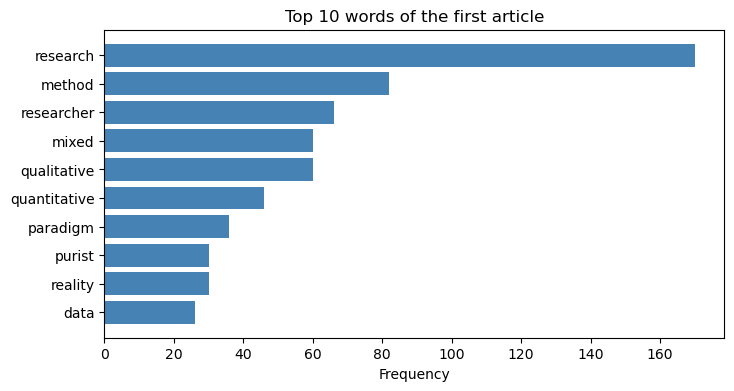

In [8]:
from nltk.tokenize import sent_tokenize, word_tokenize
import matplotlib.pyplot as plt

article = df["content"][0]
sentences = sent_tokenize(article)

word_counts = {}
for word in clean_text(article).split():
    if word in word_counts:
        word_counts[word] += 1
    else:
        word_counts[word] = 1

sentence_scores = {}
for sentence in sentences:
    score = 0
    for word in word_tokenize(sentence.lower()):
        if word in word_counts:
            score += word_counts[word]
    sentence_scores[sentence] = score

# top 5 highest score
top_sentences = sorted(sentence_scores, key=sentence_scores.get, reverse=True)[:5]
summary = " ".join(top_sentences)
print(summary)

# top 10 words
top_words = sorted(word_counts.items(), key=lambda x: x[1], reverse=True)[:10]
words = [w[0] for w in top_words]
counts = [w[1] for w in top_words]

plt.figure(figsize=(8, 4))
plt.barh(words, counts, color="steelblue")
plt.gca().invert_yaxis()
plt.title("Top 10 words of the first article")
plt.xlabel("Frequency")
plt.show()

In [6]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
import numpy as np

rest = df.iloc[1:]

vectorizer = CountVectorizer(max_df=0.9, min_df=2)
dtm = vectorizer.fit_transform(rest["clean_content"])
vocab = vectorizer.get_feature_names_out()

num_topics = 4
lda = LatentDirichletAllocation(n_components=num_topics, random_state=42)
lda.fit(dtm)

for i in range(num_topics):
    top_ids = lda.components_[i].argsort()[-10:][::-1]
    top_words = [vocab[j] for j in top_ids]
    print("Topic", i, ":", ", ".join(top_words))

Topic 0 : data, design, development, method, multiple, social, field, case, bias, change
Topic 1 : science, education, instrument, cronbach, journal, article, reading, reliability, author, issue
Topic 2 : main, full, offered, illustrate, illustrated, explicit, status, article, effect, self
Topic 3 : main, full, offered, illustrate, illustrated, explicit, status, article, effect, self


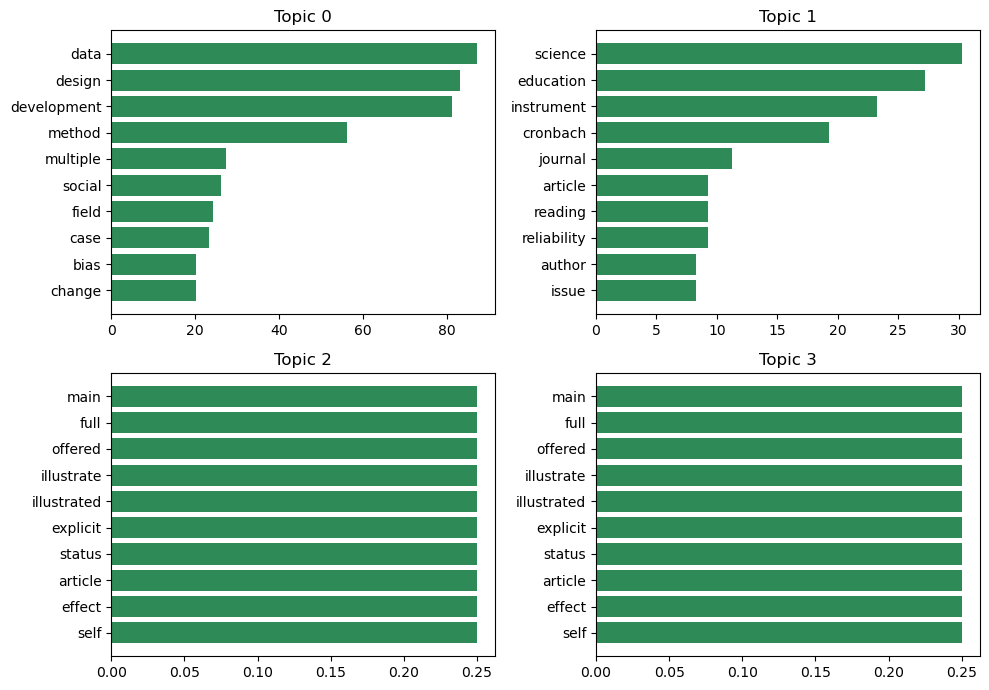

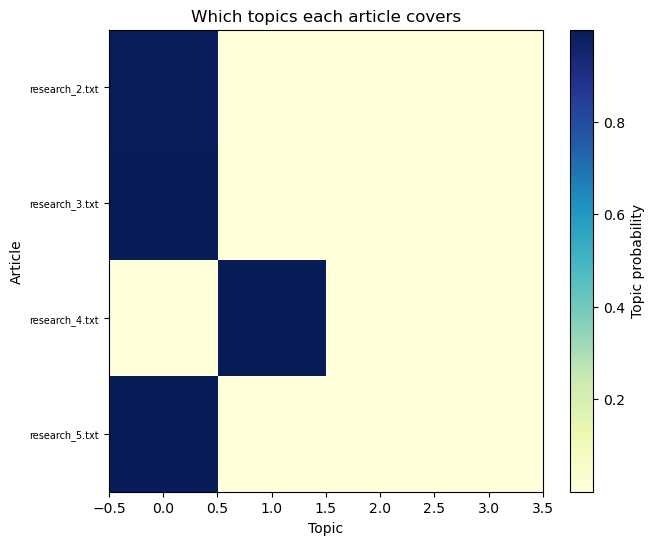

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
axes = axes.flatten()

for i in range(num_topics):
    top_ids = lda.components_[i].argsort()[-10:]
    words = [vocab[j] for j in top_ids]
    weights = lda.components_[i][top_ids]
    axes[i].barh(words, weights, color="seagreen")
    axes[i].set_title("Topic " + str(i))

plt.tight_layout()
plt.show()

doc_topics = lda.transform(dtm)

plt.figure(figsize=(7, 6))
plt.imshow(doc_topics, cmap="YlGnBu", aspect="auto")
plt.colorbar(label="Topic probability")
plt.xlabel("Topic")
plt.ylabel("Article")
plt.yticks(range(len(rest)), rest["article"].str[:25], fontsize=7)
plt.title("Which topics each article covers")
plt.show()

In [9]:
vectorizer = CountVectorizer(max_df=0.9, min_df=2)
dtm = vectorizer.fit_transform(df["clean_content"])
vocab = vectorizer.get_feature_names_out()

num_topics = 4
lda = LatentDirichletAllocation(n_components=num_topics, random_state=42, max_iter=30)
lda.fit(dtm)

# topic word lists with their weights
for i in range(num_topics):
    top_ids = lda.components_[i].argsort()[-10:][::-1]
    words = []
    for j in top_ids:
        weight = lda.components_[i][j] / lda.components_[i].sum()
        words.append(vocab[j] + " (" + str(round(weight, 3)) + ")")
    print("Topic", i, ":", ", ".join(words))

Topic 0 : data (0.056), triangulation (0.052), method (0.033), design (0.025), multiple (0.017), social (0.016), bias (0.013), source (0.012), mixed (0.012), case (0.012)
Topic 1 : method (0.044), mixed (0.032), quantitative (0.025), paradigm (0.019), reality (0.016), data (0.014), social (0.011), position (0.01), also (0.01), value (0.009)
Topic 2 : science (0.041), alpha (0.037), education (0.037), instrument (0.031), cronbach (0.026), journal (0.015), test (0.015), measure (0.014), article (0.012), reading (0.012)
Topic 3 : development (0.064), design (0.035), evaluation (0.022), model (0.015), field (0.013), orientation (0.012), term (0.011), analysis (0.01), system (0.01), specific (0.01)


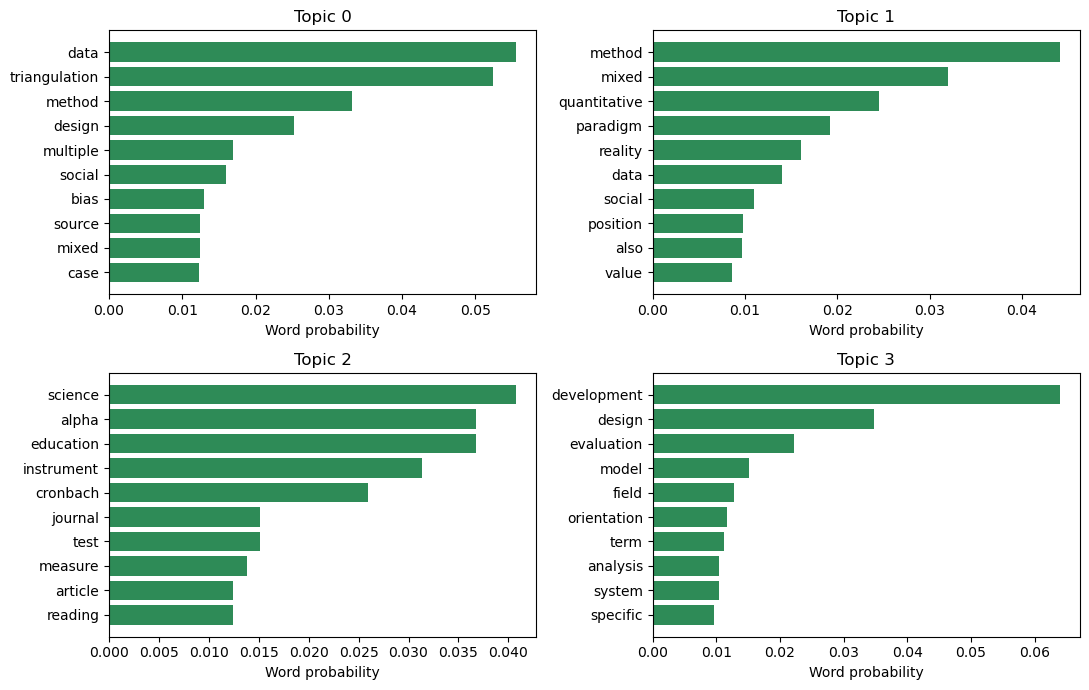

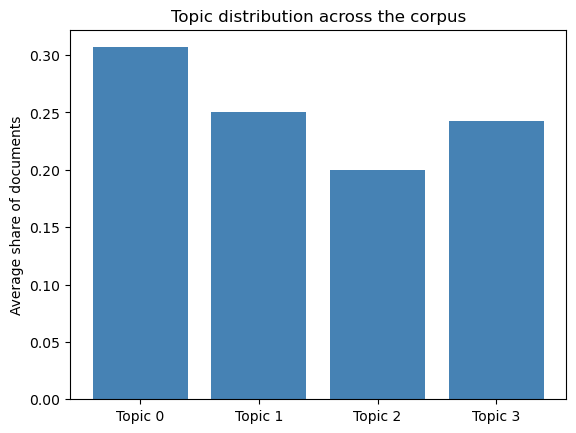

   Topic 0  Topic 1  Topic 2  Topic 3         Article  Main topic
0     0.00     1.00      0.0     0.00  research_1.txt           1
1     0.53     0.25      0.0     0.21  research_2.txt           0
2     0.00     0.00      0.0     1.00  research_3.txt           3
3     0.00     0.00      1.0     0.00  research_4.txt           2
4     1.00     0.00      0.0     0.00  research_5.txt           0


In [10]:
# top words per topic
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
axes = axes.flatten()

for i in range(num_topics):
    top_ids = lda.components_[i].argsort()[-10:]
    words = [vocab[j] for j in top_ids]
    weights = lda.components_[i][top_ids] / lda.components_[i].sum()
    axes[i].barh(words, weights, color="seagreen")
    axes[i].set_title("Topic " + str(i))
    axes[i].set_xlabel("Word probability")

plt.tight_layout()
plt.show()

# how much of the corpus each topic covers
doc_topics = lda.transform(dtm)
topic_share = doc_topics.mean(axis=0)

plt.bar(["Topic " + str(i) for i in range(num_topics)], topic_share, color="steelblue")
plt.ylabel("Average share of documents")
plt.title("Topic distribution across the corpus")
plt.show()

# article by topic table
topic_table = pd.DataFrame(doc_topics, columns=["Topic " + str(i) for i in range(num_topics)])
topic_table["Article"] = df["article"].values
topic_table["Main topic"] = doc_topics.argmax(axis=1)
print(topic_table.round(2))

In [11]:
import pyLDAvis
import pyLDAvis.lda_model

pyLDAvis.enable_notebook()
panel = pyLDAvis.lda_model.prepare(lda, dtm, vectorizer, mds="mmds")
panel

C:\Users\dikel\anaconda3\Lib\site-packages\sklearn\manifold\_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
1     -0.133842 -0.068377       1        1  35.735779
0     -0.122037  0.125566       2        1  28.908761
3      0.084587 -0.152162       3        1  23.123077
2      0.171292  0.094974       4        1  12.232382, topic_info=              Term        Freq       Total Category  logprob  loglift
159    development   79.000000   79.000000  Default  30.0000  30.0000
563  triangulation   75.000000   75.000000  Default  29.0000  29.0000
139           data  103.000000  103.000000  Default  28.0000  28.0000
482        science   37.000000   37.000000  Default  27.0000  27.0000
21           alpha   24.000000   24.000000  Default  26.0000  26.0000
..             ...         ...         ...      ...      ...      ...
220          field    6.594123   30.465918   Topic4  -4.4995   0.5707
578          value    4.995578   25.778720   Topic4  -4.7771   0.4601
159    development    5.793814   79.807057   Topic4  -4.6289  -0.5217
415       practice    3.396948   11.285522   Topic4  -5.1628   0.9004
523        student    3.396869   18.570573   Topic4  -5.1628   0.4024

[239 rows x 6 columns], token_table=      Topic      Freq     Term
term                          
0         2  0.780376  ability
0         3  0.222965  ability
6         1  0.680254   across
6         2  0.170064   across
6         4  0.085032   across
...     ...       ...      ...
583       2  0.136939   versus
585       3  0.768233   viewed
585       4  0.192058   viewed
595       1  0.821633  written
595       2  0.136939  written

[400 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[2, 1, 4, 3])